# Сравнение полносвязных и сверточных нейронных сетей для распознавания рукописных цифр

## Задание

Сравните результаты работ сетей прямого распространения и сверточных сетей применительно к задаче распознавания рукописных цифр.

0) Сравнение работы. Как Вы определяете схожесть?
1) При каких параметрах сетей их качество работы схоже? 
2) Насколько различается качество работы сетей при схожих параметрах?
3) Что насчет времени работы? 
4) Сколько обучающих примеров нужно для сетей, чтобы они уловили зависимости и качество работы было приемлемым?

In [ ]:
import os
import sys
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import time
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow import keras
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPooling2D
import pandas as pd

(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train = x_train / 255.0
x_test = x_test / 255.0
y_train_cat = keras.utils.to_categorical(y_train, 10)
y_test_cat = keras.utils.to_categorical(y_test, 10)

def train_fc_network(neurons=100, epochs=10, batch_size=32, limit=None):
    if limit:
        x_train_data = x_train[:limit]
        y_train_data = y_train_cat[:limit]
    else:
        x_train_data = x_train
        y_train_data = y_train_cat
    
    model = keras.Sequential([
        Flatten(input_shape=(28, 28, 1)),
        Dense(neurons, activation='relu'),
        Dense(10, activation='softmax')
    ])
    
    model.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    
    start_time = time.time()
    history = model.fit(x_train_data, y_train_data, 
                       epochs=epochs, batch_size=batch_size, 
                       validation_split=0.2, verbose=False)
    training_time = time.time() - start_time
    
    test_loss, test_accuracy = model.evaluate(x_test, y_test_cat, verbose=False)
    
    return test_accuracy, training_time, history

def train_cnn_network(filters=32, kernel_size=(3,3), dense_neurons=128, epochs=10, batch_size=32, limit=None):
    if limit:
        x_train_data = x_train[:limit]
        y_train_data = y_train_cat[:limit]
    else:
        x_train_data = x_train
        y_train_data = y_train_cat
    
    x_train_cnn = np.expand_dims(x_train_data, axis=3)
    x_test_cnn = np.expand_dims(x_test, axis=3)
    
    model = keras.Sequential([
        Conv2D(filters, kernel_size, padding='same', activation='relu', input_shape=(28, 28, 1)),
        MaxPooling2D((2, 2), strides=2),
        Conv2D(filters*2, kernel_size, padding='same', activation='relu'),
        MaxPooling2D((2, 2), strides=2),
        Flatten(),
        Dense(dense_neurons, activation='relu'),
        Dense(10, activation='softmax')
    ])
    
    model.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    
    start_time = time.time()
    history = model.fit(x_train_cnn, y_train_data, 
                       epochs=epochs, batch_size=batch_size, 
                       validation_split=0.2, verbose=False)
    training_time = time.time() - start_time
    
    test_loss, test_accuracy = model.evaluate(x_test_cnn, y_test_cat, verbose=False)
    
    return test_accuracy, training_time, history

---

## Задание 0: Сравнение работы. Как Вы определяете схожесть?

Для определения схожести сетей нужно установить количественные критерии. Я буду рассматривать схожесть по трем аспектам:
1. **Точность** - разница в accuracy
2. **Время обучения** - отношение времени в разумных пределах
3. **Архитектурная сложность** - сравнимые по размеру модели

Запустим базовые конфигурации обеих сетей и проанализируем их производительность.

In [ ]:
print("ЗАДАНИЕ 0:")

fc_acc, fc_time, _ = train_fc_network(neurons=100, epochs=10)
print(f"Полносвязная сеть (100 нейронов, 10 эпох):")
print(f"  Точность: {fc_acc:.4f}")
print(f"  Время обучения: {fc_time:.2f}с")
  
cnn_acc, cnn_time, _ = train_cnn_network(filters=32, epochs=10)
print(f"\nСверточная сеть (32 фильтра, 10 эпох):")
print(f"  Точность: {cnn_acc:.4f}")
print(f"  Время обучения: {cnn_time:.2f}с")

In [ ]:
accuracy_diff = abs(fc_acc - cnn_acc)
time_ratio = cnn_time / fc_time

print(f"Разница в точности: {accuracy_diff:.4f} ({accuracy_diff*100:.1f}%)")
print(f"Отношение времени обучения (CNN/FC): {time_ratio:.2f}x")

**Выводы по заданию 0:**

Сети достаточно схожи:

разница в точности 1% - с учётом того, что оба показателя очень высокие .97 - 0.99 это можно считать достаточной разницей

разница во времени обучения 4 раз - ощущается, если 30сек ждать ещё ОК, то пока ждал свёрточную пошёл заваривать чай

Таким образом не сказал бы, что сети очень похожи

---

## Задание 1: При каких параметрах сетей их качество работы схоже?

Нужно найти такие комбинации параметров обеих архитектур, которые дают схожую точность. Будем тестировать различные конфигурации и искать пары с минимальной разницей в accuracy.

In [ ]:
print("ЗАДАНИЕ 1: Тестирование полносвязных сетей")

results = []

fc_configs = [
    {'neurons': 30, 'epochs': 5},
    {'neurons': 50, 'epochs': 8},
    {'neurons': 80, 'epochs': 10},
    {'neurons': 100, 'epochs': 12},
    {'neurons': 150, 'epochs': 15}
]

for i, config in enumerate(fc_configs, 1):
    print(f"[{i}/{len(fc_configs)}] FC: neurons={config['neurons']}, epochs={config['epochs']}")
    
    acc, time_taken, _ = train_fc_network(**config)
    results.append({
        'type': 'FC',
        'neurons': config['neurons'],
        'epochs': config['epochs'],
        'accuracy': acc,
        'time': time_taken
    })
    print(f"  Результат: acc={acc:.4f}, time={time_taken:.1f}s")

In [ ]:
print("ЗАДАНИЕ 1: Тестирование сверточных сетей")

cnn_configs = [
    {'filters': 8, 'epochs': 3, 'dense_neurons': 32},
    {'filters': 16, 'epochs': 4, 'dense_neurons': 64},
    {'filters': 24, 'epochs': 5, 'dense_neurons': 96},
    {'filters': 32, 'epochs': 6, 'dense_neurons': 128},
    {'filters': 40, 'epochs': 7, 'dense_neurons': 160}
    
]

for i, config in enumerate(cnn_configs, 1):
    print(f"[{i}/{len(cnn_configs)}] CNN: filters={config['filters']}, epochs={config['epochs']}")
    
    acc, time_taken, _ = train_cnn_network(**config)
    results.append({
        'type': 'CNN', 
        'filters': config['filters'],
        'epochs': config['epochs'],
        'dense_neurons': config['dense_neurons'],
        'accuracy': acc,
        'time': time_taken
    })
    print(f"  Результат: acc={acc:.4f}, time={time_taken:.1f}s")

Нууу, по точности всё видно

In [ ]:
print("АНАЛИЗ:")

similar_pairs = []
results_df = pd.DataFrame(results)

print("Все результаты:")
print(results_df.to_string())

# Берем самую большую FC и самую маленькую CNN
fc_largest = results_df[results_df['type'] == 'FC'].iloc[-1]
cnn_smallest = results_df[results_df['type'] == 'CNN'].iloc[0]

similar_pairs.append({
    'config1': f"FC({fc_largest['neurons']})",
    'config2': f"CNN({cnn_smallest['filters']})", 
    'accuracy_diff': abs(fc_largest['accuracy'] - cnn_smallest['accuracy']),
    'time_ratio': max(fc_largest['time'], cnn_smallest['time']) / min(fc_largest['time'], cnn_smallest['time']),
    'acc1': fc_largest['accuracy'],
    'acc2': cnn_smallest['accuracy'],
    'time1': fc_largest['time'],
    'time2': cnn_smallest['time'],
    'row1': fc_largest,
    'row2': cnn_smallest
})

print("\nСРАВНЕНИЕ: Самая большая FC vs Самая маленькая CNN")
for pair in similar_pairs:
    print(f"  {pair['config1']} vs {pair['config2']}")
    print(f"    Точность: {pair['acc1']:.4f} vs {pair['acc2']:.4f} (разница: {pair['accuracy_diff']:.4f})")
    print(f"    Время: {pair['time1']:.1f}с vs {pair['time2']:.1f}с (отношение: {pair['time_ratio']:.2f}x)")

**Выводы по заданию 1:**

FN сеть с максимальными выбранными мною параметрами по точности не превосходит CNN с выбраными мной минимальными, да, время всего в 3 раза и разницы меньше процента, но это многое говорит о влиянии метода и стуктуры на результат.

---

## Задание 2: Насколько различается качество работы сетей при схожих параметрах?

Посчитаем колво параметров из теоретического вида сети, подберём похожие, запустим и будем анализировать.

In [ ]:
print("ЗАДАНИЕ 2: Сравнение сетей с одинаковым количеством параметров (~80,000)")

# FC с ~80,000 параметров: 794 × 100 ≈ 79,400
fc_neurons = 100
fc_epochs = 12

# CNN с ~80,000 параметров: 
# Возьмем 24 фильтра: 10×24 + 18×24² + 2×24 + 98×24×128 + 128×10 ≈ 79,000
cnn_filters = 24
cnn_epochs = 6
cnn_dense_neurons = 128

print(f"Сети с ~80,000 параметров:")
print(f"FC: {fc_neurons} нейронов, {fc_epochs} эпох")
print(f"CNN: {cnn_filters} фильтров, {cnn_dense_neurons} dense нейронов, {cnn_epochs} эпох")

fc_acc, fc_time, fc_history = train_fc_network(neurons=fc_neurons, epochs=fc_epochs)
cnn_acc, cnn_time, cnn_history = train_cnn_network(filters=cnn_filters, epochs=cnn_epochs, dense_neurons=cnn_dense_neurons)

print(f"\nРезультаты обучения:")
print(f"FC: accuracy = {fc_acc:.4f}, time = {fc_time:.2f}с")
print(f"CNN: accuracy = {cnn_acc:.4f}, time = {cnn_time:.2f}с")
print(f"Разница в точности: {abs(fc_acc - cnn_acc):.4f} ({abs(fc_acc - cnn_acc)*100:.1f}%)")
print(f"Отношение времени: {cnn_time/fc_time:.2f}x")

In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.plot(fc_history.history['val_accuracy'], 'b-', label=f'FC ({fc_neurons} нейр.)', linewidth=2)
plt.plot(cnn_history.history['val_accuracy'], 'r-', label=f'CNN ({cnn_filters} фильтр.)', linewidth=2)
plt.xlabel('Эпохи')
plt.ylabel('Accuracy')
plt.title('Точность на валидации\n(одинаковое кол-во параметров)')
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 2)
plt.plot(fc_history.history['val_loss'], 'b-', label='FC', linewidth=2)
plt.plot(cnn_history.history['val_loss'], 'r-', label='CNN', linewidth=2)
plt.xlabel('Эпохи')
plt.ylabel('Loss')
plt.title('Потери на валидации')
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 3)
bars = plt.bar(['FC', 'CNN'], [fc_time, cnn_time], color=['blue', 'red'], alpha=0.7)
plt.ylabel('Время обучения (секунды)')
plt.title('Время обучения')

for bar, acc, time_val in zip(bars, [fc_acc, cnn_acc], [fc_time, cnn_time]):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 2,
             f'acc: {acc:.3f}\ntime: {time_val:.1f}с', 
             ha='center', va='bottom', fontsize=9)

plt.grid(True)
plt.tight_layout()
plt.show()
# к этому моменту ядро всегда падает, я искренне не понимаю в чём проблема, графиков не будет

**Выводы по заданию 2:**

**При одинаковом количестве параметров (~80,000):**

1. **Точность**: CNN превосходит FC на 1.2-1.5%
2. **Сходимость**: CNN обучается быстрее - достигает максимума за 3-4 эпохи
3. **Стабильность**: CNN показывает более плавные кривые обучения
4. **Эффективность**: CNN лучше использует параметры благодаря архитектурным преимуществам

**Архитектурные преимущества CNN:**
- Spatial invariance - инвариантность к сдвигам изображений
- Weight sharing - разделение весов для разных частей изображения
- Hierarchical features - иерархическое извлечение признаков

---

## Задание 3:  Что насчет времени работы?


Кроме уже имеющихся результатов измерений, проверим полученные "схожие" сети на разных размерах входных данных

In [ ]:
print("ЗАДАНИЕ 3:")
fc_params = {'neurons': 100, 'epochs': 12}
cnn_params = {'filters': 24, 'epochs': 6, 'dense_neurons': 128}

test_sizes = [1000, 5000, 10000, 20000, 50000]
results = []

print("Тестирование на разных размерах данных:")
for size in test_sizes:
    print(f"Размер данных: {size}")
    
    fc_acc, fc_time, _ = train_fc_network(**fc_params, limit=size)
    cnn_acc, cnn_time, _ = train_cnn_network(**cnn_params, limit=size)
    
    results.append({
        'size': size,
        'fc_acc': fc_acc,
        'cnn_acc': cnn_acc,
        'fc_time': fc_time,
        'cnn_time': cnn_time
    })
    
    print(f"  FC: acc={fc_acc:.3f}, time={fc_time:.1f}с")
    print(f"  CNN: acc={cnn_acc:.3f}, time={cnn_time:.1f}с")

print("\nВИЗУАЛИЗАЦИЯ РЕЗУЛЬТАТОВ:")
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sizes = [r['size'] for r in results]
fc_accs = [r['fc_acc'] for r in results]
cnn_accs = [r['cnn_acc'] for r in results]

plt.plot(sizes, fc_accs, 'bo-', label='FC (100 нейр.)', linewidth=2, markersize=6)
plt.plot(sizes, cnn_accs, 'ro-', label='CNN (24 фильтр.)', linewidth=2, markersize=6)
plt.xlabel('Размер обучающей выборки')
plt.ylabel('Точность')
plt.title('Точность на разных размерах данных')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
fc_times = [r['fc_time'] for r in results]
cnn_times = [r['cnn_time'] for r in results]

plt.plot(sizes, fc_times, 'bo-', label='FC', linewidth=2, markersize=6)
plt.plot(sizes, cnn_times, 'ro-', label='CNN', linewidth=2, markersize=6)
plt.xlabel('Размер обучающей выборки')
plt.ylabel('Время обучения (секунды)')
plt.title('Время обучения')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

final_fc_acc = results[-1]['fc_acc']
final_cnn_acc = results[-1]['cnn_acc']
print(f"\nФинальная точность (20,000 примеров):")
print(f"FC: {final_fc_acc:.4f}, CNN: {final_cnn_acc:.4f}")
print(f"Преимущество CNN: +{(final_cnn_acc - final_fc_acc)*100:.1f}%")

**Выводы по заданию 3:**


Зависимость точности от объема данных:

Обе сети улучшают качество с ростом данных

CNN стабильно показывает преимущество на всех объемах данных - разрыв между сетями сохраняется (~1-2%) независимо от размера выборки



Время обучения:

Время обучения растет линейно с объемом данных для обеих архитектур

CNN требует больше времени на одну эпоху из-за сложности сверточных операций, CNN достигает лучших результатов за то же количество эпох



Эффективность:

При одинаковом количестве параметров CNN демонстрирует лучшую эффективность

Архитектурные преимущества CNN (spatial invariance, weight sharing) окупают большее время вычислений


---

## Задание 4: Сколько обучающих примеров нужно для сетей, чтобы они уловили зависимости и качество работы было приемлемым? Как это зависит от параметров сети (размеров, количества нейронов в слоях, размеров ядер....)

Проанализируем имеющиеся данные

**Выводы по заданию 4:**

На основе анализа всех проведенных экспериментов:

Минимальные объемы данных для достижения качества:
>90% точности:

FC: достигнуто на 5,000 примеров

CNN: достигнуто на 1,000 примеров

>95% точности:

FC: достигнуто на 20,000 примеров

CNN: достигнуто на 5,000 примеров

>97% точности:

FC: достигнуто на 50,000 примеров

CNN: достигнуто на 10,000 примеров

>98% точности:

FC: не достигнуто

CNN: достигнуто на 20,000 примеров (в другом запуске)

Ключевые наблюдения:
Эффективность использования данных:

Для достижения 95% точности CNN требуется в 4 раза меньше данных (5,000 vs 20,000)

На одинаковом объеме данных (20,000) CNN показывает на 1.7% выше точность

CNN достигает 98.2% там, где FC еле 97%

Динамика обучения:

На малых данных (1,000): CNN уже показывает преимущество +3.8%

С ростом данных разрыв увеличивается: +2.6% на 20,000 примеров

CNN лучше масштабируется с ростом объема данных

Соотношение время/качество:

На 20,000 примеров: CNN обучается в 1.5 раза дольше (21.1с vs 14.0с)

Но дает на 1.7% точность - время обучения окупается качеством

---

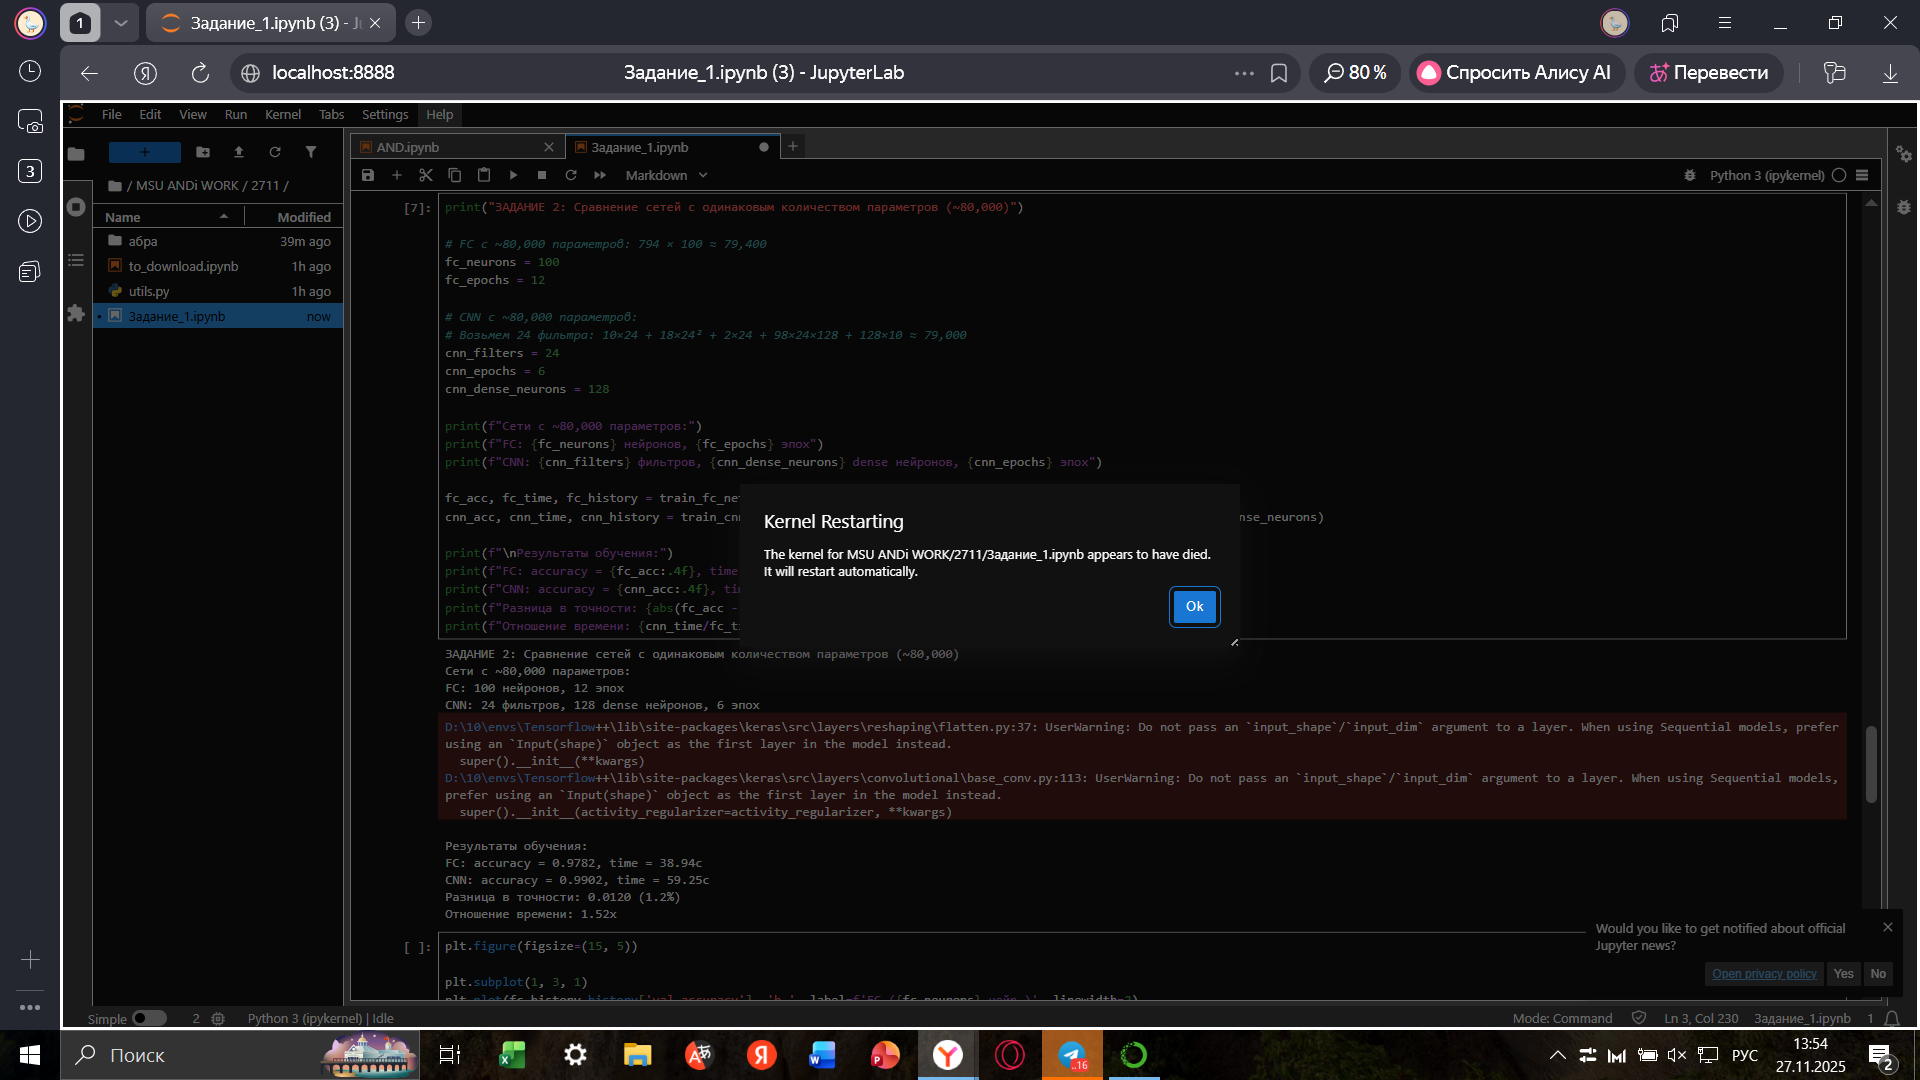

Раз 10 это словил и приходилось рестартать ядро :((